# 요약 압축과 Compress

**이 노트북에서 할 일**

1. 메시지 6개를 그대로 모델에 보내고 모델이 받은 메시지 수를 셉니다(Before).
2. 요약 미들웨어를 등록해 오래된 메시지를 요약 한 개로 바꿉니다(After).
3. 요약문에 중요한 조건이 남았는지 확인하고, 남길 메시지 수를 바꿔 봅니다.

**준비물** — `.env` 파일의 `OPENAI_API_KEY`. 데이터 파일은 없습니다. 모델 호출은 5번이고 실행 시간은 1분 이내입니다. 예상 비용은 0.01달러 미만입니다.

## 오늘 볼 그림

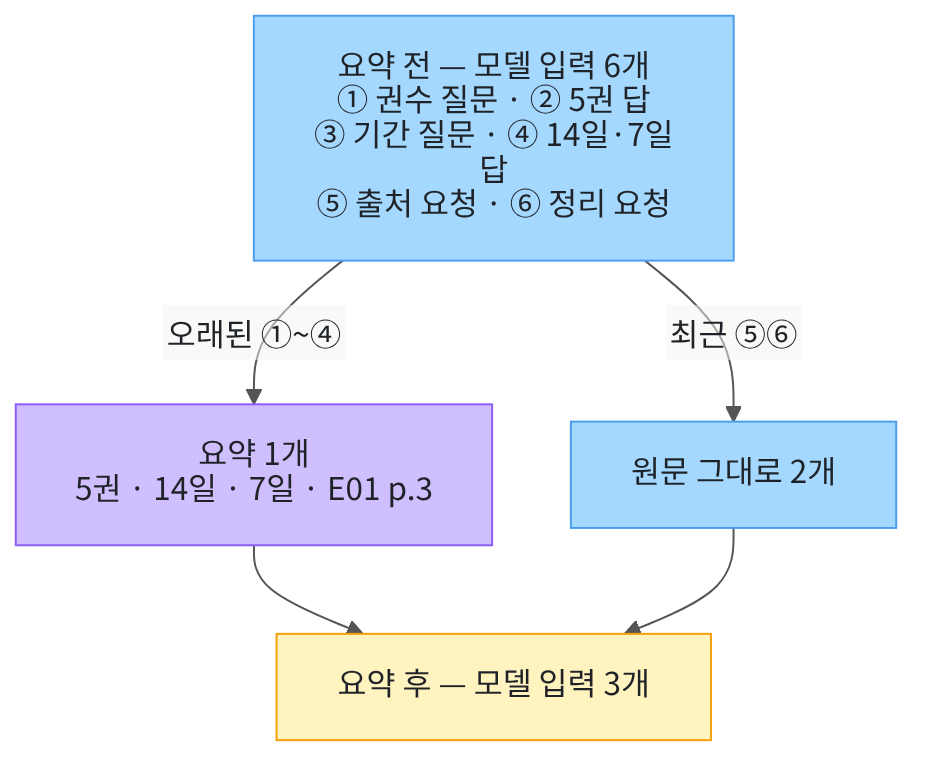

위가 요약 전, 아래가 요약 후입니다. 오래된 메시지 네 개가 요약 한 개가 되고 최근 두 개는 그대로 남습니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11


이번 절에서 쓰는 이름을 불러옵니다. 오래된 대화를 요약하는 미들웨어는 `SummarizationMiddleware`입니다.

In [2]:
# 에이전트·미들웨어·메시지·모델을 만드는 도구를 불러옵니다
from collections.abc import Callable

from langchain.agents import create_agent
from langchain.agents.middleware import ModelRequest, ModelResponse, SummarizationMiddleware
from langchain.agents.middleware import wrap_model_call
from langchain.chat_models import init_chat_model
from langchain_core.messages import AIMessage, HumanMessage

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다. 01절과 같은 설정입니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-15에 이 모델로 실행한 결과입니다.

## 2. 긴 대화 준비

대화가 길어지면 모델에 보내는 글이 늘어납니다. 요약 압축은 오래된 메시지를 짧은 요약 하나로 바꿔 입력을 줄이는 방법입니다.
Ch8에서 배운 Compress 전략을 미들웨어로 적용하는 것입니다. 먼저 도서관 대출 조건을 묻는 메시지 6개를 만듭니다.

메시지를 만드는 클래스 중 `HumanMessage`는 사용자 메시지, `AIMessage`는 모델 메시지입니다.
마지막 두 개는 사용자가 연달아 보낸 요청입니다. 에이전트는 마지막 사용자 요청에 답합니다.

In [5]:
# 사용자와 모델이 주고받은 메시지 6개를 만듭니다
history = [
    HumanMessage("대출은 몇 권까지 되나요?"),
    AIMessage("한 번에 5권까지 빌릴 수 있습니다. [E01 p.3]"),
    HumanMessage("대출 기간은요?"),
    AIMessage("14일이며, 예약자가 없으면 7일 연장할 수 있습니다. [E01 p.3]"),
    HumanMessage("출처도 같이 기억해 주세요."),
    HumanMessage("지금까지 말한 대출 조건을 정리해 주세요."),
]
print("대화 메시지 수:", len(history))

대화 메시지 수: 6


**결과 읽기** — 대화 메시지 수는 `6`입니다. 권수 5권, 기간 14일, 연장 7일, 출처 E01 p.3가 중요한 조건입니다.

02절과 같은 기록 훅을 만듭니다. 모델이 받은 메시지를 목록에 적습니다.

In [6]:
# 모델이 실제로 받은 메시지를 기록하는 훅을 만듭니다
seen_by_model = []


@wrap_model_call
def record_model_input(request: ModelRequest, handler: Callable) -> ModelResponse:
    for message in request.messages:
        seen_by_model.append(message.text)
    return handler(request)

출력은 없습니다.

## 3. Before — 대화 전체 보내기

요약 없이 메시지 6개를 모두 보냅니다.

In [7]:
# Before: 요약 없이 대화 전체를 보냅니다
plain_agent = create_agent(model, tools=[], middleware=[record_model_input])
plain_agent.invoke({"messages": history})
print("모델이 받은 메시지 수:", len(seen_by_model))

모델이 받은 메시지 수: 6


**결과 읽기** — 모델이 받은 메시지 수는 `6`입니다. 메시지가 100개로 늘면 100개를 모두 보내게 됩니다.

## 4. After — 요약 미들웨어 등록하기

`SummarizationMiddleware()` 클래스에 인자 세 개를 넘깁니다. 인자 `model`은 요약문을 만들 모델입니다.
인자 `trigger=("messages", 4)`는 메시지가 4개 이상이면 요약을 시작하라는 뜻입니다.
인자 `keep=("messages", 2)`는 가장 최근 메시지 2개는 요약하지 말고 그대로 두라는 뜻입니다.

In [8]:
# After: 메시지가 4개 이상이면 최근 2개만 남기고 요약하는 미들웨어를 만듭니다
summarizer = SummarizationMiddleware(model=model, trigger=("messages", 4), keep=("messages", 2))
print("미들웨어 이름:", summarizer.name)

미들웨어 이름: SummarizationMiddleware


**결과 읽기** — 미들웨어 이름 `SummarizationMiddleware`가 출력됩니다.

기록을 비우고 같은 대화를 보냅니다. 요약 미들웨어도 before_model 자리에서 실행됩니다.
그래서 모델 호출을 감싸는 기록 훅은 요약이 끝난 메시지를 봅니다.

In [9]:
# 같은 대화를 요약 미들웨어가 있는 에이전트로 보냅니다
seen_by_model.clear()
summary_agent = create_agent(model, tools=[], middleware=[summarizer, record_model_input])
summary_result = summary_agent.invoke({"messages": history})
print("모델이 받은 메시지 수:", len(seen_by_model))

모델이 받은 메시지 수: 3


**결과 읽기** — 모델이 받은 메시지 수가 `3`으로 줄었습니다. 요약 1개와 최근 메시지 2개입니다.

모델이 받은 메시지를 하나씩 출력해 봅니다.

In [10]:
# 모델이 받은 메시지를 번호와 함께 출력합니다
for number, text in enumerate(seen_by_model, start=1):
    print(number, "|", text)

1 | Here is a summary of the conversation to date:

## SESSION INTENT

사용자는 도서 대출 규정을 문의하고 있으며, 현재까지는 대출 가능 권수와 대출 기간/연장 가능 여부를 확인하는 것이 목적이다.

## SUMMARY

- 대출 가능 권수: 한 번에 5권까지 가능함. [E01 p.3]
- 대출 기간: 14일임. [E01 p.3]
- 연장: 예약자가 없으면 7일 연장 가능함. [E01 p.3]

## ARTIFACTS

None

## NEXT STEPS

- 사용자가 추가로 도서관 이용 규정(반납, 연체, 예약 등)을 묻는 경우 해당 정보를 이어서 제공한다.
2 | 출처도 같이 기억해 주세요.
3 | 지금까지 말한 대출 조건을 정리해 주세요.


**결과 읽기** — 1번은 `Here is a summary`로 시작하는 요약문입니다. 이 앞부분은 미들웨어 코드가 붙이는 고정 문구입니다.
그 뒤의 소제목과 내용은 요약 지시문에 따라 모델이 썼습니다. 그래서 실행마다 달라질 수 있습니다.
2번과 3번은 원래 대화의 마지막 두 메시지와 같습니다.

In [11]:
# 요약문에 중요한 조건 네 가지가 남았는지 하나씩 확인합니다
summary_text = seen_by_model[0]
for condition in ["5권", "14일", "7일", "E01 p.3"]:
    print(condition, "남음:", condition in summary_text)
assert len(seen_by_model) == 3
assert summary_text.startswith("Here is a summary")

5권 남음: True
14일 남음: True
7일 남음: True
E01 p.3 남음: True


**결과 읽기** — 이번 실행에서는 네 조건 모두 `True`입니다. 결과에 False가 있으면 그 조건은 요약하면서 사라진 것입니다.
`assert` 두 줄은 모델 문장과 상관없이 늘 같아야 하는 값(메시지 수와 고정 문구)만 확인합니다.

요약으로 메시지 수는 줄었습니다. 글자 수도 줄었는지, 저장된 대화 기록은 어떻게 됐는지 확인합니다.

In [12]:
# 요약 전후의 모델 입력 글자 수와 저장된 대화 기록 수를 비교합니다
before_chars = 0
for message in history:
    before_chars = before_chars + len(message.text)
after_chars = 0
for text in seen_by_model:
    after_chars = after_chars + len(text)
print("요약 전 모델 입력 글자 수:", before_chars)
print("요약 후 모델 입력 글자 수:", after_chars)
print("저장된 대화 기록 수:", len(summary_result["messages"]))
for message in summary_result["messages"]:
    print("-", message.type, "|", message.text[:20])

요약 전 모델 입력 글자 수: 130
요약 후 모델 입력 글자 수: 381
저장된 대화 기록 수: 4
- human | Here is a summary of
- human | 출처도 같이 기억해 주세요.
- human | 지금까지 말한 대출 조건을 정리해 주
- ai | 물론입니다. 지금까지 확인된 **도서


**결과 읽기** — 요약 전 글자 수는 `130`, 요약 후 글자 수는 `381`입니다. 짧은 대화라 요약문이 원문보다 길었습니다.
저장된 대화 기록 수는 `4`입니다. 첫 메시지는 `Here is a summary`로 시작하는 요약문입니다.
다음 두 개는 최근 메시지이고, 마지막 ai 메시지가 모델의 새 답입니다.

## 5. 값 하나 바꿔 보기 — 남길 메시지 수

`keep` 값을 2에서 4로 바꿉니다. 실행 전에 예상해 봅니다. 요약 1개와 최근 4개, 모두 5개가 될 것입니다.

In [13]:
# 최근 메시지를 4개 남기도록 바꿔 같은 대화를 보냅니다
keep_four = SummarizationMiddleware(model=model, trigger=("messages", 4), keep=("messages", 4))
seen_by_model.clear()
keep_four_agent = create_agent(model, tools=[], middleware=[keep_four, record_model_input])
keep_four_agent.invoke({"messages": history})
print("모델이 받은 메시지 수:", len(seen_by_model))
for number, text in enumerate(seen_by_model, start=1):
    print(number, "|", text[:30])

모델이 받은 메시지 수: 5
1 | Here is a summary of the conve
2 | 대출 기간은요?
3 | 14일이며, 예약자가 없으면 7일 연장할 수 있습니다.
4 | 출처도 같이 기억해 주세요.
5 | 지금까지 말한 대출 조건을 정리해 주세요.


**결과 읽기** — 모델이 받은 메시지 수가 `5`입니다. 1번은 요약문이고, 2~5번은 원래 대화의 마지막 네 메시지입니다.
남길 메시지가 많을수록 입력은 덜 줄지만 원문이 더 많이 보존됩니다.

## 정리

- 요약 미들웨어는 메시지 수가 기준 이상이면 오래된 메시지를 요약 하나로 바꿉니다.
- 최근 메시지는 `keep` 값만큼 원문 그대로 남습니다.
- 요약문은 모델이 만들므로 권수·기간·출처 같은 조건이 빠질 수 있습니다. 중요한 조건은 요약에 맡기지 말고 따로 저장합니다.